In [33]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

In [34]:
import jax
jax.config.update("jax_enable_x64", True)

import jax.numpy as jnp
from flax import linen as nn
import optax
import copy

from typing import Callable

from functools import partial

import tensorflow as tf
import tensorrt

from pyDOE import lhs
import numpy as np
import matplotlib.pyplot as plt

from scipy.integrate import odeint

import numpy as np

from jax.scipy.optimize import minimize
from scipy.optimize import fsolve

import warnings
import math

from collections import deque

In [35]:
print("Num GPUs Available: ", len(tf.config.list_physical_devices('GPU')))

Num GPUs Available:  1


In [36]:
print(jax.default_backend())

gpu


In [37]:
t0, tfinal = 0.0, 1.0

In [38]:
def TodaLatt(w, t):
    
    p1, q1, p2, q2, p3, q3 = w

    p1_t = -jnp.exp(q1 - q2)
    q1_t = p1

    p2_t = jnp.exp(q1 - q2) - jnp.exp(q2 - q3)
    q2_t = p2

    p3_t = jnp.exp(q2 - q3)
    q3_t = p3

    dwdt = [p1_t, q1_t, p2_t, q2_t, p3_t, q3_t]

    return dwdt

In [39]:
@jax.jit
def compute_H(p1, p2, p3, q1, q2, q3):

    a1 = -0.5*p1
    a2 = -0.5*p2
    a3 = -0.5*p3

    b1 = 0.5*jnp.exp(0.5*(q1-q2))
    b2 = 0.5*jnp.exp(0.5*(q2-q3))
    b3 = 0.0

    main_diag = jnp.array([a1, a2, a3])
    sub_diag = jnp.array([b1, b2])
    super_diag = jnp.array([b1, b2])

    print(main_diag.shape)

    L_main = jnp.diag(main_diag)
    L_sub = jnp.diag(sub_diag, k=-1)
    L_super = jnp.diag(super_diag, k=1)
    
    L = jnp.diag(main_diag) + jnp.diag(sub_diag, k=-1) + jnp.diag(super_diag, k=1)
    evals, evecs = jnp.linalg.eigh(L)
    
    L_2 = L@L
    H_L = 2*jnp.trace(L_2)

    return H_L, evals

@jax.jit
def get_H(p1, p2, p3, q1, q2, q3):
  return jax.vmap(compute_H, [0, 0, 0, 0, 0, 0])(p1, p2, p3, q1, q2, q3)

In [40]:
n = 500
t = np.linspace(t0, tfinal, n)

p1_init = np.random.uniform(-1.0, 1.0, size=(1,))
q1_init = np.random.uniform(-1.0, 1.0, size=(1,))
p2_init = np.random.uniform(-1.0, 1.0, size=(1,))
q2_init = np.random.uniform(-1.0, 1.0, size=(1,))
p3_init = np.random.uniform(-1.0, 1.0, size=(1,))
q3_init = np.random.uniform(-1.0, 1.0, size=(1,))
H_init = (p1_init**2)/2 + (p2_init**2)/2 + (p3_init**2)/2 + jnp.exp(q1_init - q2_init) + jnp.exp(q2_init - q3_init)

data_rk = np.column_stack([p1_init, q1_init, p2_init, q2_init, p3_init, q3_init])
data_rk = np.reshape(data_rk, (-1,))
t_rk = t

sol_rk = odeint(TodaLatt, data_rk, t_rk, rtol = 1e-13, atol = 1e-13)
p1_rk, q1_rk, p2_rk, q2_rk, p3_rk, q3_rk = sol_rk[:, 0], sol_rk[:, 1], sol_rk[:, 2], sol_rk[:, 3], sol_rk[:, 4], sol_rk[:, 5]
H_rk = (p1_rk**2)/2 + (p2_rk**2)/2 + (p3_rk**2)/2 + jnp.exp(q1_rk - q2_rk) + jnp.exp(q2_rk - q3_rk)

In [41]:
print(H_init)

[2.55378415]


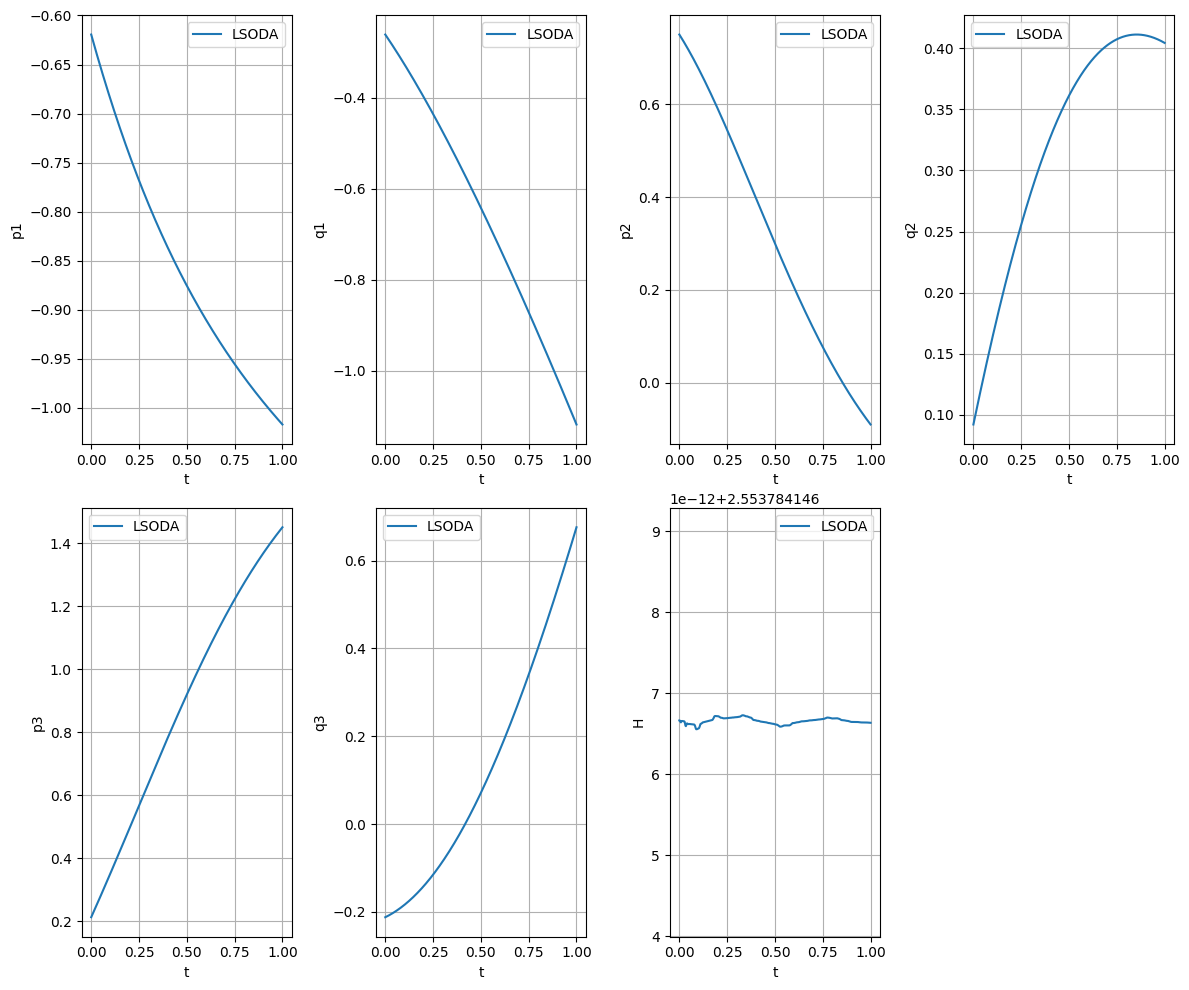

In [42]:
fig = plt.figure(figsize=(12, 10))

plt.subplot(2, 4, 1)
plt.tight_layout()
plt.plot(t, p1_rk, label = 'LSODA')
plt.xlabel("t")
plt.ylabel("p1")
plt.grid()
plt.legend()

plt.subplot(2, 4, 2)
plt.tight_layout()
plt.plot(t, q1_rk, label = 'LSODA')
plt.xlabel("t")
plt.ylabel("q1")
plt.grid()
plt.legend()

plt.subplot(2, 4, 3)
plt.tight_layout()
plt.plot(t, p2_rk, label = 'LSODA')
plt.xlabel("t")
plt.ylabel("p2")
plt.grid()
plt.legend()

plt.subplot(2, 4, 4)
plt.tight_layout()
plt.plot(t, q2_rk, label = 'LSODA')
plt.xlabel("t")
plt.ylabel("q2")
plt.grid()
plt.legend()

plt.subplot(2, 4, 5)
plt.tight_layout()
plt.plot(t, p3_rk, label = 'LSODA')
plt.xlabel("t")
plt.ylabel("p3")
plt.grid()
plt.legend()

plt.subplot(2, 4, 6)
plt.tight_layout()
plt.plot(t, q3_rk, label = 'LSODA')
plt.xlabel("t")
plt.ylabel("q3")
plt.grid()
plt.legend()

plt.subplot(2, 4, 7)
plt.tight_layout()
plt.plot(t, H_rk, label = 'LSODA')
plt.xlabel("t")
plt.ylabel("H")
plt.grid()
plt.legend()

In [43]:
class Normalize(nn.Module):
  xmin: float
  xmax: float

  @nn.compact
  def __call__(self, x):
    return 2.0*(x-self.xmin)/(self.xmax - self.xmin) - 1.0

In [44]:
class HardConstraint(nn.Module):
  t0: float
  tfinal: float
  u0: float

  @nn.compact
  def __call__(self, inputs):
    t, nn = inputs
    return self.u0 + (t-self.t0)/(self.tfinal-self.t0)*nn

In [45]:
class CombineBranches(nn.Module):
  @nn.compact
  def __call__(self, inp1, inp2):
    mult = jnp.sum(inp1*inp2, axis=1)
    out = jnp.reshape(mult, (-1,1))
    return out

In [46]:
class MLP(nn.Module):

  layers: int
  units: int

  @nn.compact
  def __call__(self, inp):
    b = inp
    for i in range(self.layers-1):
      b = nn.Dense(self.units)(b)
      b = nn.tanh(b)
    out = nn.Dense(6*self.units)(b)
    return out

In [47]:
def define_collocation_points(t_bdry, N=100):

    ode_points = t_bdry[0] + (t_bdry[1] - t_bdry[0])*lhs(1, N)

    p1s = np.random.uniform(-1.0, 1.0, size=(N, 1))
    q1s = np.random.uniform(-1.0, 1.0, size=(N, 1))
    p2s = np.random.uniform(-1.0, 1.0, size=(N, 1))
    q2s = np.random.uniform(-1.0, 1.0, size=(N, 1))
    p3s = np.random.uniform(-1.0, 1.0, size=(N, 1))
    q3s = np.random.uniform(-1.0, 1.0, size=(N, 1))
    Hs = (p1s**2)/2 + (p2s**2)/2 + (p3s**2)/2 + jnp.exp(q1s - q2s) + jnp.exp(q2s - q3s)

    _, evals = jax.vmap(compute_H, [0, 0, 0, 0, 0, 0])(p1s.reshape(-1), p2s.reshape(-1), p3s.reshape(-1), q1s.reshape(-1), q2s.reshape(-1), q3s.reshape(-1))


    ode_points = np.column_stack((ode_points, Hs, evals))
    zsensors = np.column_stack((p1s, q1s, p2s, q2s, p3s, q3s))
    
    return (ode_points, zsensors)

In [48]:
(de_points, zsensors) = define_collocation_points([t0, tfinal], 1000)
print(de_points.shape, zsensors.shape)

(3,)
(1000, 5) (1000, 6)


In [49]:
class VDeepONet(nn.Module):

  t0: float
  tfinal: float
  layers: int
  units: int

  @nn.compact
  def __call__(self, t, u):

    if u.ndim == 1:
      u = jnp.reshape(u, (1,-1))

    if t.ndim == 1:
      t = jnp.reshape(t, (1,-1)) 

    t_0 = t[:, :1]
    H_0 = t[:, 1:]
      
    t_0 = jnp.reshape(t_0, (-1,1))
    t_0_norm = Normalize(self.t0, self.tfinal)(t_0)
   
    p1_0 = u[:, :1]
    q1_0 = u[:, 1:2]
    p2_0 = u[:, 2:3]
    q2_0 = u[:, 3:4]
    p3_0 = u[:, 4:5]
    q3_0 = u[:, 5:]

    u = jnp.column_stack((p1_0, q1_0, p2_0, q2_0, p3_0, q3_0))

    b = t_0_norm
    #b = jnp.column_stack((t_0_norm, H_0))

    trunk_net = MLP(self.layers, self.units)(b)
    branch_net = MLP(self.layers, self.units)(u)

    trunk_p1 = trunk_net[:, :self.units]
    trunk_q1 = trunk_net[:, self.units:2*self.units]
    trunk_p2 = trunk_net[:, 2*self.units:3*self.units]
    trunk_q2 = trunk_net[:, 3*self.units:4*self.units]
    trunk_p3 = trunk_net[:, 4*self.units:5*self.units]
    trunk_q3 = trunk_net[:, 5*self.units:]
      
    branch_p1 = branch_net[:, :self.units]
    branch_q1 = branch_net[:, self.units:2*self.units]
    branch_p2 = branch_net[:, 2*self.units:3*self.units]
    branch_q2 = branch_net[:, 3*self.units:4*self.units]
    branch_p3 = branch_net[:, 4*self.units:5*self.units]
    branch_q3 = branch_net[:, 5*self.units:]
      
    p1 = CombineBranches()(trunk_p1, branch_p1)
    q1 = CombineBranches()(trunk_q1, branch_q1)
    p2 = CombineBranches()(trunk_p2, branch_p2)
    q2 = CombineBranches()(trunk_q2, branch_q2)
    p3 = CombineBranches()(trunk_p3, branch_p3)
    q3 = CombineBranches()(trunk_q3, branch_q3)
      
    p1 = HardConstraint(self.t0, self.tfinal, p1_0)([t_0, p1])
    q1 = HardConstraint(self.t0, self.tfinal, q1_0)([t_0, q1])
    p2 = HardConstraint(self.t0, self.tfinal, p2_0)([t_0, p2])
    q2 = HardConstraint(self.t0, self.tfinal, q2_0)([t_0, q2])
    p3 = HardConstraint(self.t0, self.tfinal, p3_0)([t_0, p3])
    q3 = HardConstraint(self.t0, self.tfinal, q3_0)([t_0, q3])
      
    p1 = jnp.reshape(p1, (-1,))
    q1 = jnp.reshape(q1, (-1,))
    p2 = jnp.reshape(p2, (-1,))
    q2 = jnp.reshape(q2, (-1,))
    p3 = jnp.reshape(p3, (-1,))
    q3 = jnp.reshape(q3, (-1,))

    return p1, q1, p2, q2, p3, q3

In [50]:
@partial(jax.jit, static_argnums=(2,))
def Vvar_model(t, z, component, params):
  return Vdeeponet.apply(params, t, z)[component][0]

@partial(jax.jit, static_argnums=(2,))
def Vvar(t, z, component, params):
  return jax.vmap(Vvar_model, [0, 0, None, None])(t, z, component, params)

@partial(jax.jit, static_argnums=(2,))
def Vvar_t(t, z, component, params):
  return jax.vmap(jax.grad(Vvar_model, 0), [0, 0, None, None])(t, z, component, params)


@jax.jit
def Vloss(params, t, z):
    
    p1_t_loss_w = 1.0
    q1_t_loss_w = 1.0
    p2_t_loss_w = 1.0
    q2_t_loss_w = 1.0
    p3_t_loss_w = 1.0
    q3_t_loss_w = 1.0    
    
    diff_loss_w = 1.0
    H_loss_w = 1.0

    H_0 = t[:, -1]
    
    p1_0 = z[:, :1]
    q1_0 = z[:, 1:2]
    p2_0 = z[:, 2:3]
    q2_0 = z[:, 3:4]
    p3_0 = z[:, 4:5]
    q3_0 = z[:, 5:]
    
    p1 = Vvar(t, z, 0, params)
    q1 = Vvar(t, z, 1, params)
    p2 = Vvar(t, z, 2, params)
    q2 = Vvar(t, z, 3, params)
    p3 = Vvar(t, z, 4, params)
    q3 = Vvar(t, z, 5, params)
    
    H = (p1**2)/2 + (p2**2)/2 + (p3**2)/2 + jnp.exp(q1 - q2) + jnp.exp(q2 - q3)
    
    dp1_t = Vvar_t(t, z, 0, params)
    dq1_t = Vvar_t(t, z, 1, params)
    dp2_t = Vvar_t(t, z, 2, params)
    dq2_t = Vvar_t(t, z, 3, params)
    dp3_t = Vvar_t(t, z, 4, params)
    dq3_t = Vvar_t(t, z, 5, params)
        
    p1_t = dp1_t[:, 0]
    q1_t = dq1_t[:, 0]  
    p2_t = dp2_t[:, 0]
    q2_t = dq2_t[:, 0]
    p3_t = dp3_t[:, 0]
    q3_t = dq3_t[:, 0]
    
    H_loss = H - H_0
    H_loss = jnp.square(H_loss)
    H_loss = jnp.mean(H_loss)

    p1_t_loss = p1_t + jnp.exp(q1 - q2)
    p1_t_loss = jnp.square(p1_t_loss)
    p1_t_loss = jnp.mean(p1_t_loss)

    q1_t_loss = q1_t - p1
    q1_t_loss = jnp.square(q1_t_loss)
    q1_t_loss = jnp.mean(q1_t_loss)
    
    p2_t_loss = p2_t - (jnp.exp(q1 - q2) - jnp.exp(q2 - q3))
    p2_t_loss = jnp.square(p2_t_loss)
    p2_t_loss = jnp.mean(p2_t_loss)
    
    q2_t_loss = q2_t - p2
    q2_t_loss = jnp.square(q2_t_loss)
    q2_t_loss = jnp.mean(q2_t_loss)

    p3_t_loss = p3_t - jnp.exp(q2 - q3)
    p3_t_loss = jnp.square(p3_t_loss)
    p3_t_loss = jnp.mean(p3_t_loss)
    
    q3_t_loss = q3_t - p3
    q3_t_loss = jnp.square(q3_t_loss)
    q3_t_loss = jnp.mean(q3_t_loss)
        
    diff_loss = p1_t_loss_w*p1_t_loss +  q1_t_loss_w*q1_t_loss + p2_t_loss_w*p2_t_loss + q2_t_loss_w*q2_t_loss + \
                p3_t_loss_w*p3_t_loss + q3_t_loss_w*q3_t_loss

    total_loss = diff_loss_w*diff_loss + H_loss_w*H_loss

    return total_loss

@jax.jit
def Vtrain_step(params, pdes, z):
    t = pdes[:, :]
    
    return jax.value_and_grad(Vloss, has_aux = False)(params, t, z)

@partial(jax.jit, static_argnums=(3,))
def Voptimize(grads, opt_state, params, optimizer_update):
    updates, opt_state = optimizer_update(grads, opt_state, params)
    params = optax.apply_updates(params, updates)
    return params, opt_state

In [51]:
def Vtrain_network(params, des, sensors, epochs=100):

    N = de_points.shape[0]
    
    nr_batches = 10
    batch_size = len(des)//nr_batches
    
    print("batch size:", batch_size)
    
    lr = 1e-3
    optimizer = optax.adam(lr)
    opt_state = optimizer.init(params)
    
    ds_z = tf.data.Dataset.from_tensor_slices(sensors)
    ds_de = tf.data.Dataset.from_tensor_slices(des)
    
    ds = tf.data.Dataset.zip((ds_de, ds_z))
    ds = ds.shuffle(N).batch(batch_size)
    
    epoch_loss = np.zeros(epochs)

    for i in range(epochs):

        for (des_batch, z_batch) in ds:

            loss, grads = Vtrain_step(params, des_batch.numpy(), z_batch.numpy())
            params, opt_state = Voptimize(grads, opt_state, params, optimizer.update)

            epoch_loss[i] += loss

        epoch_loss[i] /= batch_size

        if i % 500  == 0:
            print(f'Loss in epoch {i}: {epoch_loss[i]}')

    return params, epoch_loss

In [52]:
Vdeeponet = VDeepONet(t0, tfinal, layers=4, units=40)

t_init = jnp.full((10, 2), 1.0)
u_init = jnp.full((10, 6), 1.0)

Vparams = Vdeeponet.init(jax.random.PRNGKey(0), t_init, u_init)

In [53]:
Vparam_count = sum(x.size for x in jax.tree.leaves(Vparams))
print(Vparam_count)

26600


In [54]:
print(de_points.shape, zsensors.shape)

(1000, 5) (1000, 6)


batch size: 100
Loss in epoch 0: 1.8725205578868098
Loss in epoch 500: 0.15847460176300254
Loss in epoch 1000: 0.05679142121895651
Loss in epoch 1500: 0.03560806367448939
Loss in epoch 2000: 0.021550312962707548


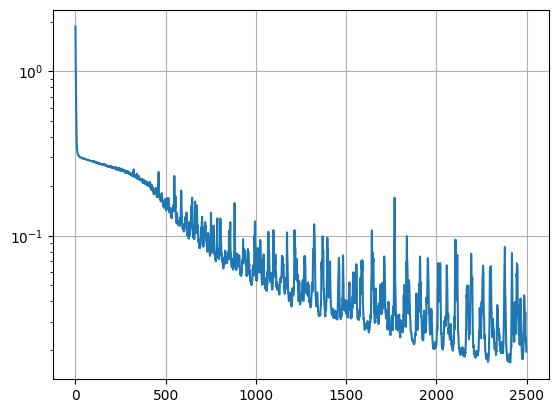

In [55]:
epochs = 2500
Vparams, Vloss = Vtrain_network(Vparams, de_points, zsensors, epochs)

plt.semilogy(Vloss)
plt.grid()

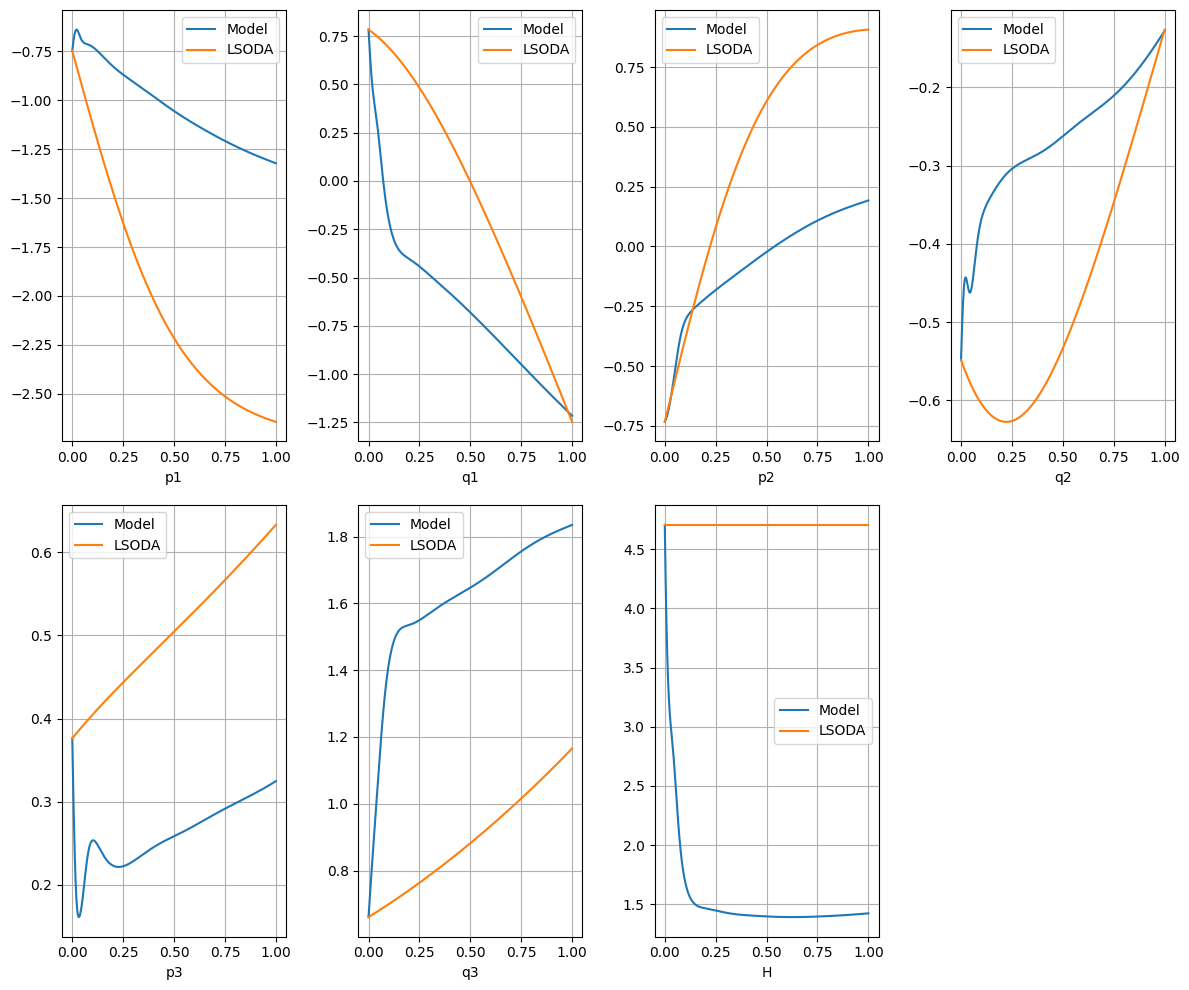

In [56]:
n = 500
t = np.linspace(t0, tfinal, n)

p1_init = np.random.uniform(-1.0, 1.0, size=(1,))
q1_init = np.random.uniform(-1.0, 1.0, size=(1,))
p2_init = np.random.uniform(-1.0, 1.0, size=(1,))
q2_init = np.random.uniform(-1.0, 1.0, size=(1,))
p3_init = np.random.uniform(-1.0, 1.0, size=(1,))
q3_init = np.random.uniform(-1.0, 1.0, size=(1,))
H_init = (p1_init**2)/2 + (p2_init**2)/2 + (p3_init**2)/2 + jnp.exp(q1_init - q2_init) + jnp.exp(q2_init - q3_init)

data_model = np.column_stack([p1_init, q1_init, p2_init, q2_init, p3_init, q3_init])
data_model = np.reshape(data_model, (-1,))
data_model = np.repeat(np.expand_dims(data_model, axis=0), n, axis=0)

H_model = np.repeat(np.expand_dims(H_init, axis=0), n, axis=0)
t_model = np.column_stack([t, H_model])

p1 = jax.vmap(Vvar_model, [0, 0, None, None])(t_model, data_model, 0, Vparams)
q1 = jax.vmap(Vvar_model, [0, 0, None, None])(t_model, data_model, 1, Vparams)
p2 = jax.vmap(Vvar_model, [0, 0, None, None])(t_model, data_model, 2, Vparams)
q2 = jax.vmap(Vvar_model, [0, 0, None, None])(t_model, data_model, 3, Vparams)
p3 = jax.vmap(Vvar_model, [0, 0, None, None])(t_model, data_model, 4, Vparams)
q3 = jax.vmap(Vvar_model, [0, 0, None, None])(t_model, data_model, 5, Vparams)
H = (p1**2)/2 + (p2**2)/2 + (p3**2)/2 + jnp.exp(q1 - q2) + jnp.exp(q2 - q3)

data_rk = np.column_stack([p1_init, q1_init, p2_init, q2_init, p3_init, q3_init])
data_rk = np.reshape(data_rk, (-1,))
t_rk = t

sol_rk = odeint(TodaLatt, data_rk, t_rk, rtol = 1e-13, atol = 1e-13)
p1_rk, q1_rk, p2_rk, q2_rk, p3_rk, q3_rk = sol_rk[:, 0], sol_rk[:, 1], sol_rk[:, 2], sol_rk[:, 3], sol_rk[:, 4], sol_rk[:, 5]
H_rk = (p1_rk**2)/2 + (p2_rk**2)/2 + (p3_rk**2)/2 + jnp.exp(q1_rk - q2_rk) + jnp.exp(q2_rk - q3_rk)

fig = plt.figure(figsize=(12, 10))

plt.subplot(2, 4, 1)
plt.tight_layout()
plt.plot(t, p1, label = 'Model')
plt.plot(t, p1_rk, label = 'LSODA')
plt.xlabel("p1")
plt.grid()
plt.legend()

plt.subplot(2, 4, 2)
plt.tight_layout()
plt.plot(t, q1, label = 'Model')
plt.plot(t, q1_rk, label = 'LSODA')
plt.xlabel("q1")
plt.grid()
plt.legend()

plt.subplot(2, 4, 3)
plt.tight_layout()
plt.plot(t, p2, label = 'Model')
plt.plot(t, p2_rk, label = 'LSODA')
plt.xlabel("p2")
plt.grid()
plt.legend()

plt.subplot(2, 4, 4)
plt.tight_layout()
plt.plot(t, q2, label = 'Model')
plt.plot(t, q2_rk, label = 'LSODA')
plt.xlabel("q2")
plt.grid()
plt.legend()

plt.subplot(2, 4, 5)
plt.tight_layout()
plt.plot(t, p3, label = 'Model')
plt.plot(t, p3_rk, label = 'LSODA')
plt.xlabel("p3")
plt.grid()
plt.legend()

plt.subplot(2, 4, 6)
plt.tight_layout()
plt.plot(t, q3, label = 'Model')
plt.plot(t, q3_rk, label = 'LSODA')
plt.xlabel("q3")
plt.grid()
plt.legend()

plt.subplot(2, 4, 7)
plt.tight_layout()
plt.plot(t, H, label = 'Model')
plt.plot(t, H_rk, label = 'LSODA')
plt.xlabel("H")
plt.grid()
plt.legend()